In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score)
#202531177

In [2]:
df = pd.read_csv("02_diabetes.csv")

print(df.head())
print(df.shape)

#202531177

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
(100000, 9)


In [3]:

df.info()
display(df.describe())
print("\nNilai Null")
df.isnull().sum()
#202531177

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000



Nilai Null


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [4]:
print("Gender Categories")
print(df['gender'].value_counts())

print("\nSmoking History Categories")
print(df['smoking_history'].value_counts())

print("\nHypertension Distribution")
print(df['hypertension'].value_counts())

print("\nHeart Disease Distribution")
print(df['heart_disease'].value_counts())

print("\nDiabetes Distribution (Target)")
print(df['diabetes'].value_counts())

# 202531177

Gender Categories
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Smoking History Categories
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

Hypertension Distribution
hypertension
0    92515
1     7485
Name: count, dtype: int64

Heart Disease Distribution
heart_disease
0    96058
1     3942
Name: count, dtype: int64

Diabetes Distribution (Target)
diabetes
0    91500
1     8500
Name: count, dtype: int64


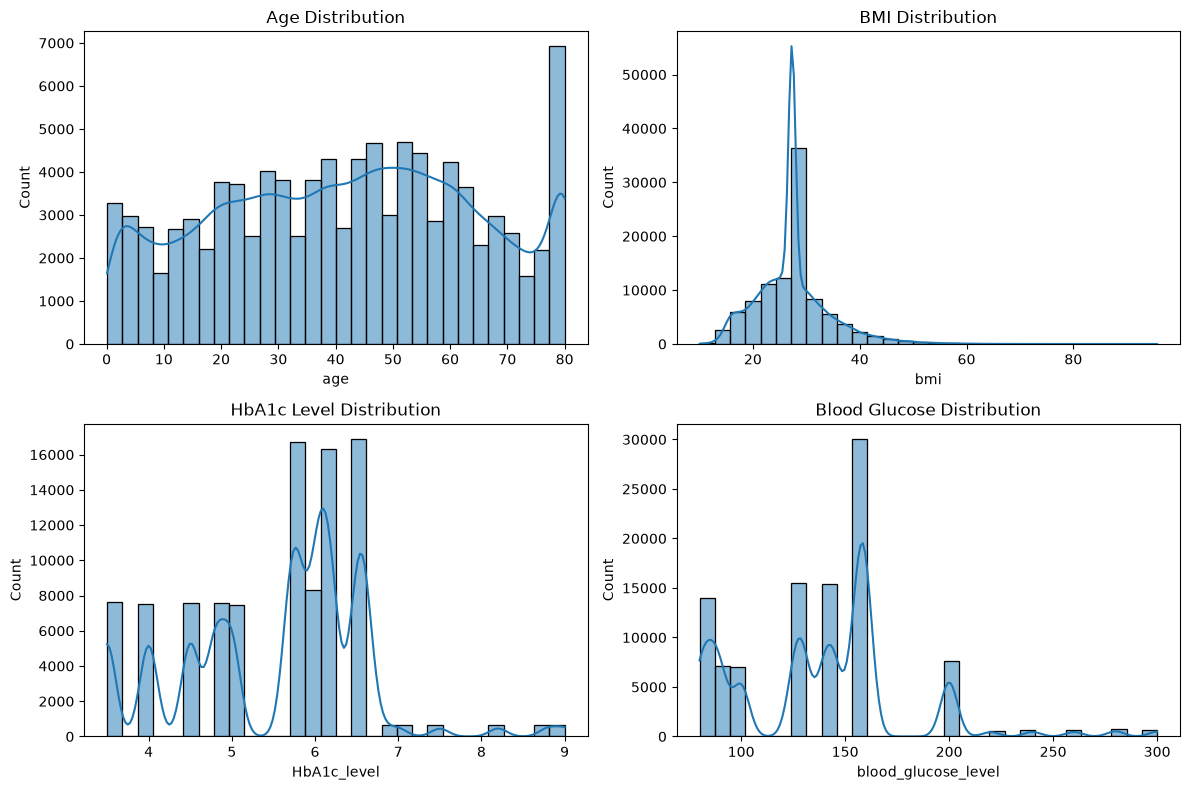

In [5]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Age Distribution')

plt.subplot(2, 2, 2)
sns.histplot(df['bmi'], bins=30, kde=True)
plt.title('BMI Distribution')

plt.subplot(2, 2, 3)
sns.histplot(df['HbA1c_level'], bins=30, kde=True)
plt.title('HbA1c Level Distribution')

plt.subplot(2, 2, 4)
sns.histplot(df['blood_glucose_level'], bins=30, kde=True)
plt.title('Blood Glucose Distribution')

plt.tight_layout()
plt.show()

# 202531177

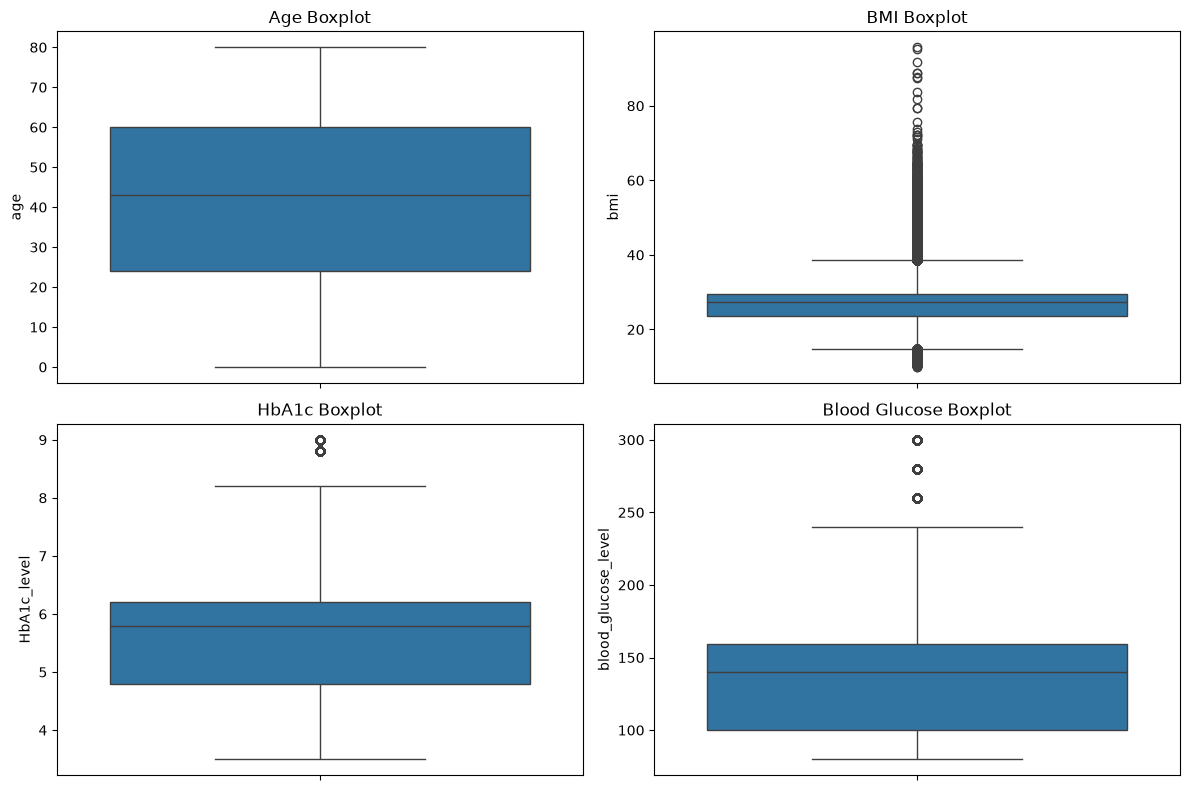

In [6]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.boxplot(y=df['age'])
plt.title('Age Boxplot')

plt.subplot(2, 2, 2)
sns.boxplot(y=df['bmi'])
plt.title('BMI Boxplot')

plt.subplot(2, 2, 3)
sns.boxplot(y=df['HbA1c_level'])
plt.title('HbA1c Boxplot')

plt.subplot(2, 2, 4)
sns.boxplot(y=df['blood_glucose_level'])
plt.title('Blood Glucose Boxplot')

plt.tight_layout()
plt.show()

# 202531177

In [7]:
columns = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\n{col}")
    print("Batas Bawah:", lower_bound)
    print("Batas Atas:", upper_bound)
    print("Jumlah Outlier:", len(outliers))

# 202531177


age
Batas Bawah: -30.0
Batas Atas: 114.0
Jumlah Outlier: 0

bmi
Batas Bawah: 14.705
Batas Atas: 38.504999999999995
Jumlah Outlier: 7086

HbA1c_level
Batas Bawah: 2.6999999999999993
Batas Atas: 8.3
Jumlah Outlier: 1315

blood_glucose_level
Batas Bawah: 11.5
Batas Atas: 247.5
Jumlah Outlier: 2038


In [8]:
print("Duplicate Records:")
print(df.duplicated().sum())

# 202531177

Duplicate Records:
3854


In [9]:
print("Dataset Awal:", df.shape)

df = df.drop_duplicates()

print("Dataset setelah data duplikat dihapus:", df.shape)

# 202531177

Dataset Awal: (100000, 9)
Dataset setelah data duplikat dihapus: (96146, 9)


In [10]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature:", X.shape)
print("Target:", y.shape)

# 202531177

Features (X):


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,80.0,0,1,never,25.19,6.6,140
1,Female,54.0,0,0,No Info,27.32,6.6,80
2,Male,28.0,0,0,never,27.32,5.7,158
3,Female,36.0,0,0,current,23.45,5.0,155
4,Male,76.0,1,1,current,20.14,4.8,155



Target (y):


0    0
1    0
2    0
3    0
4    0
Name: diabetes, dtype: int64


Feature: (96146, 8)
Target: (96146,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# 202531177

Training Features: (76916, 8)
Testing Features: (19230, 8)

Training Target: (76916,)
Testing Target: (19230,)


In [12]:
categorical_features = ['gender', 'smoking_history']

numerical_features = [
    'age',
    'hypertension',
    'heart_disease',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

# 202531177

In [13]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

# 202531177

Training Data Shape: (76916, 15)
Testing Data Shape: (19230, 15)


In [14]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_processed, y_train)

y_pred_knn = knn.predict(X_test_processed)

# 202531177

In [15]:
print("Akurasi KNN:")
print(accuracy_score(y_test, y_pred_knn))

# 202531177

Akurasi KNN:
0.9592823712948518


In [16]:


nb = GaussianNB()

nb.fit(X_train_processed, y_train)

y_pred_nb = nb.predict(X_test_processed)


# 202531177

In [17]:
print("Akurasi Naive Bayes:")
print(accuracy_score(y_test, y_pred_nb))

# 202531177

Akurasi Naive Bayes:
0.6227769110764431


In [18]:


comparison = pd.DataFrame({
    'KNN': {
        'Akurasi': accuracy_score(y_test, y_pred_knn),

    },
    'Naive Bayes': {
        'Akurasi': accuracy_score(y_test, y_pred_nb),

    }
})

display(comparison.round(4))

# 202531177

,KNN,Naive Bayes
Akurasi,0.9593,0.6228
